# 01 - Exploration & Validation: Breast Cancer Classification

**Stage A of the assignment - notebook first, production code second.**

This notebook is my experimentation record. Every step of the ML workflow is tried and
checked here *before* it is moved into the `production_app/` package.

| Item | Choice |
|---|---|
| Dataset | Breast Cancer Wisconsin (Diagnostic) - built into scikit-learn |
| Task | Binary classification: `malignant` vs `benign` |
| Model | Logistic Regression (inside a scikit-learn `Pipeline`) |
| Main concern | Prevent data leakage; keep preprocessing consistent at prediction time |

**Workflow validated in this notebook**

`Load data -> Inspect -> Split -> Preprocess -> Fit -> Evaluate -> Save -> Reload -> Predict`

**Table of contents**
1. Setup
2. Load the dataset
3. Inspect the data (shape, features, labels, missing values, class balance)
4. Train/test split
5. Data leakage: why the scaler must be fitted on training data only
6. Build and fit the pipeline
7. Evaluate
8. Sample prediction
9. Save the pipeline, reload it, and predict without retraining
10. Handling invalid input
11. Summary and mapping to `production_app/` modules

## 1. Setup

In [2]:
import tempfile
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Settings kept in one place. In the final app these move to config.py / .env
RANDOM_STATE = 42
TEST_SIZE = 0.2

pd.set_option("display.max_columns", 12)
print(f"scikit-learn version: {sklearn.__version__}")

Matplotlib is building the font cache; this may take a moment.


scikit-learn version: 1.9.1


## 2. Load the dataset

`load_breast_cancer()` returns a `Bunch` (a dictionary-like object).
I use `as_frame=True` so the features are a pandas `DataFrame` with real column names.

In [3]:
dataset = load_breast_cancer(as_frame=True)

print("Type:", type(dataset))
print("Keys:", list(dataset.keys()))

X = dataset.data      # DataFrame: features
y = dataset.target    # Series: labels (0 / 1)

Type: <class 'sklearn.utils._bunch.Bunch'>
Keys: ['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module']


## 3. Inspect the data

### 3.1 Dimensions

In [4]:
print("Features shape:", X.shape, "-> (n_samples, n_features)")
print("Target shape:  ", y.shape, "-> (n_samples,)")
assert X.shape[0] == y.shape[0], "Rows in X and y must match"

Features shape: (569, 30) -> (n_samples, n_features)
Target shape:   (569,) -> (n_samples,)


### 3.2 Feature names

In [5]:
feature_names = [str(n) for n in dataset.feature_names]
print(f"Number of features: {len(feature_names)}\n")
for i in range(0, len(feature_names), 10):
    print(feature_names[i : i + 10])

Number of features: 30

['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension']
['radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error']
['worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


The 30 features are 10 measurements of cell nuclei (radius, texture, perimeter, area, ...),
each given as **mean**, **standard error**, and **worst** value.

### 3.3 Class labels

In [6]:
target_names = [str(n) for n in dataset.target_names]
label_map = {i: name for i, name in enumerate(target_names)}
print("Label meaning:", label_map)

Label meaning: {0: 'malignant', 1: 'benign'}


> **Important:** in this dataset `0 = malignant` and `1 = benign`.
> Predictions are numbers, so the app must map them back to names to be readable.

### 3.4 First rows and summary statistics

In [7]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,...,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,...,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,...,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,...,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,...,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,...,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [8]:
X.describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


The features are on **very different scales** (e.g. `mean area` is in the hundreds, `mean smoothness`
is around 0.1). This is why scaling is needed for Logistic Regression.

### 3.5 Missing values and data types

In [9]:
missing = int(X.isna().sum().sum())
print("Total missing values:", missing)
print("All columns numeric:", all(pd.api.types.is_numeric_dtype(t) for t in X.dtypes))
assert missing == 0

Total missing values: 0
All columns numeric: True


### 3.6 Class distribution

,label,class,count,share_%
0,0,malignant,212,37.3
1,1,benign,357,62.7


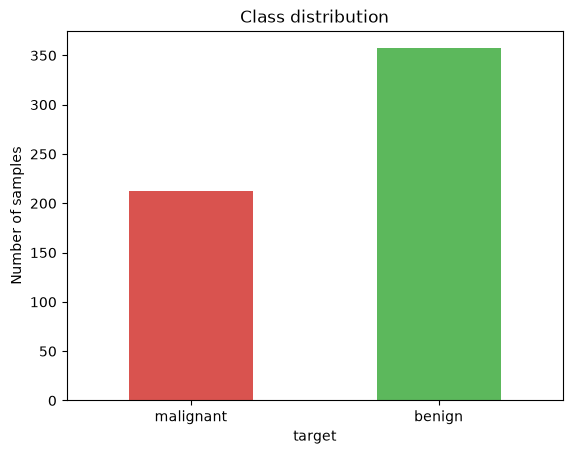

In [10]:
counts = y.value_counts().sort_index()
summary = pd.DataFrame(
    {
        "label": counts.index,
        "class": [label_map[i] for i in counts.index],
        "count": counts.values,
        "share_%": (counts.values / len(y) * 100).round(1),
    }
)
display(summary)

ax = counts.rename(index=label_map).plot(kind="bar", color=["#d9534f", "#5cb85c"], rot=0)
ax.set_title("Class distribution")
ax.set_ylabel("Number of samples")
plt.show()

**Observation:** the classes are moderately imbalanced (about 37% malignant / 63% benign).
Because of this I use a **stratified** split so train and test keep the same proportions,
and I look at precision / recall / F1 - not accuracy alone.

## 4. Train/test split

`stratify=y` keeps the class ratio equal in both sets. `random_state` makes the split reproducible.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

dist = pd.DataFrame(
    {
        "full_%": y.value_counts(normalize=True).sort_index() * 100,
        "train_%": y_train.value_counts(normalize=True).sort_index() * 100,
        "test_%": y_test.value_counts(normalize=True).sort_index() * 100,
    }
).round(1)
dist.index = [label_map[i] for i in dist.index]
display(dist)

assert len(X_train) + len(X_test) == len(X)

X_train: (455, 30) | X_test: (114, 30)
y_train: (455,) | y_test: (114,)


,full_%,train_%,test_%
malignant,37.3,37.4,36.8
benign,62.7,62.6,63.2


## 5. Data leakage check

**Rule:** anything that *learns* from data (like `StandardScaler`, which learns mean and std)
must be fitted on the **training set only**.
If it is fitted on all the data, information from the test set leaks into training.

Below I compare both ways to see the difference.

In [12]:
leaky_scaler = StandardScaler().fit(X)          # WRONG: sees test data too
correct_scaler = StandardScaler().fit(X_train)  # RIGHT: training data only

comparison = pd.DataFrame(
    {
        "leaky_mean (all data)": leaky_scaler.mean_[:5],
        "correct_mean (train only)": correct_scaler.mean_[:5],
    },
    index=feature_names[:5],
)
comparison["difference"] = comparison["leaky_mean (all data)"] - comparison["correct_mean (train only)"]
display(comparison.round(4))

,leaky_mean (all data),correct_mean (train only),difference
mean radius,14.1273,14.0672,0.0601
mean texture,19.2896,19.2474,0.0423
mean perimeter,91.9690,91.5574,0.4116
mean area,654.8891,648.5411,6.3480
mean smoothness,0.0964,0.0962,0.0002


The means are different, so the wrong way really does let test information into the scaler.

**Decision:** put the scaler and the model together in one `Pipeline`.
When I call `pipeline.fit(X_train, y_train)`, the scaler learns only from the training data,
and the *same* learned scaling is applied automatically at prediction time.

## 6. Build and fit the pipeline

In [13]:
pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]
)

pipeline.fit(X_train, y_train)
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### 6.1 Sanity checks on the fitted pipeline

In [14]:
scaler = pipeline.named_steps["scaler"]
model = pipeline.named_steps["model"]

# The scaler must have learned from the TRAIN set only
assert np.allclose(scaler.mean_, X_train.mean().values), "Scaler was not fitted on train only"

print("Scaler learned", scaler.mean_.shape[0], "feature means")
print("Model classes:", model.classes_)
print("Coefficient matrix shape:", model.coef_.shape)

Scaler learned 30 feature means
Model classes: [0 1]
Coefficient matrix shape: (1, 30)


## 7. Evaluate

### 7.1 Metrics on the test set

In [15]:
y_pred = pipeline.predict(X_test)

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision (macro)": precision_score(y_test, y_pred, average="macro"),
    "recall (macro)": recall_score(y_test, y_pred, average="macro"),
    "f1 (macro)": f1_score(y_test, y_pred, average="macro"),
}
display(pd.Series(metrics, name="test score").round(4).to_frame())

print(classification_report(y_test, y_pred, target_names=target_names))

,test score
accuracy,0.9825
precision (macro),0.9812
recall (macro),0.9812
f1 (macro),0.9812


              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



### 7.2 Confusion matrix

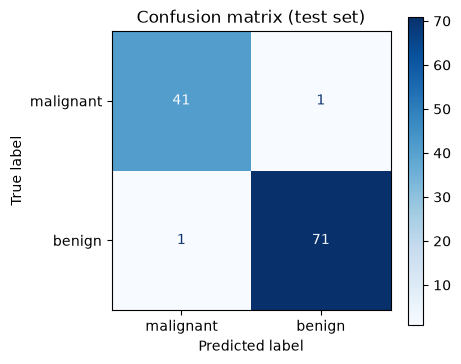

In [16]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=target_names, cmap="Blues", ax=ax
)
ax.set_title("Confusion matrix (test set)")
plt.show()

### 7.3 Is the result stable? (5-fold cross-validation on the training set)

A single split can be lucky. Cross-validation on the *training* set checks stability
without touching the test set. Because the scaler is inside the pipeline, it is re-fitted
inside each fold (no leakage here either).

In [17]:
cv_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring="accuracy")
print("CV accuracy per fold:", cv_scores.round(4))
print(f"Mean: {cv_scores.mean():.4f} | Std: {cv_scores.std():.4f}")

CV accuracy per fold: [0.967 0.978 0.967 1.    0.989]
Mean: 0.9802 | Std: 0.0128


**Result check:** the test accuracy is close to the cross-validation accuracy,
so the model is not overfitted and the baseline is valid.
For a medical task, a malignant case predicted as benign (false negative) is the most costly mistake,
so recall of the `malignant` class is the most important number to watch.

## 8. Sample prediction

In [18]:
sample = X_test.iloc[[0]]   # double brackets keep it a 1-row DataFrame
print("Sample shape:", sample.shape)

pred = int(pipeline.predict(sample)[0])
proba = pipeline.predict_proba(sample)[0]

print("Predicted label:", pred, "->", label_map[pred])
print("True label:     ", int(y_test.iloc[0]), "->", label_map[int(y_test.iloc[0])])
print("Probabilities:  ", {label_map[i]: round(float(p), 4) for i, p in enumerate(proba)})

Sample shape: (1, 30)
Predicted label: 0 -> malignant
True label:      0 -> malignant
Probabilities:   {'malignant': 1.0, 'benign': 0.0}


## 9. Save the pipeline, reload it, and predict without retraining

The saved artifact must contain **scaler + model together**.
I save to a temporary folder here so the notebook does not create files in the project;
the real app will save to `models/` through `model_service.py`.

In [19]:
with tempfile.TemporaryDirectory() as tmp_dir:
    model_path = Path(tmp_dir) / "pipeline.joblib"

    joblib.dump(pipeline, model_path)
    print("Saved:", model_path.name, f"({model_path.stat().st_size / 1024:.1f} KB)")

    loaded_pipeline = joblib.load(model_path)   # no .fit() is called after this line
    print("Reloaded object type:", type(loaded_pipeline).__name__)

    # The reloaded pipeline must behave exactly like the original
    same_predictions = np.array_equal(pipeline.predict(X_test), loaded_pipeline.predict(X_test))
    same_probabilities = np.allclose(pipeline.predict_proba(X_test), loaded_pipeline.predict_proba(X_test))
    print("Same predictions after reload:  ", same_predictions)
    print("Same probabilities after reload:", same_probabilities)
    assert same_predictions and same_probabilities

Saved: pipeline.joblib (3.0 KB)
Reloaded object type: Pipeline
Same predictions after reload:   True
Same probabilities after reload: True


## 10. Handling invalid input

The prediction code in the final app must reject bad input with a clear message instead of failing silently.
Here I try the cases I need to handle, to learn which errors scikit-learn raises.

In [20]:
def try_predict(label: str, data) -> None:
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", UserWarning)  # keep the output short
            result = pipeline.predict(data)
        print(f"[{label}] OK -> {result}")
    except Exception as exc:  # exploration only; the app will catch specific errors  # noqa: BLE001
        print(f"[{label}] {type(exc).__name__}: {str(exc).splitlines()[0]}")


try_predict("wrong number of features", np.zeros((1, 5)))
try_predict("missing values (NaN)", np.full((1, 30), np.nan))
try_predict("wrong column names", pd.DataFrame(np.zeros((1, 30)), columns=[f"c{i}" for i in range(30)]))
try_predict("valid input", sample)

[wrong number of features] ValueError: X has 5 features, but StandardScaler is expecting 30 features as input.
[missing values (NaN)] ValueError: Input X contains NaN.
[wrong column names] ValueError: The feature names should match those that were passed during fit.
[valid input] OK -> [0]


**Takeaway for `model_service.py`:**
- validate that the input has exactly 30 features, with the expected names, and no NaN
- raise a clear `ValueError` for bad input
- raise `FileNotFoundError` with a helpful message if the saved model does not exist

## 11. Summary and mapping to `production_app/`

### Validated results

In [21]:
print(f"Dataset:            {X.shape[0]} samples, {X.shape[1]} features, 2 classes")
print(f"Missing values:     {missing}")
print(f"Split:              {len(X_train)} train / {len(X_test)} test (stratified, seed={RANDOM_STATE})")
print(f"Test accuracy:      {metrics['accuracy']:.4f}")
print(f"CV accuracy (mean): {cv_scores.mean():.4f}")
print("Save -> reload -> predict: verified (identical outputs)")

Dataset:            569 samples, 30 features, 2 classes
Missing values:     0
Split:              455 train / 114 test (stratified, seed=42)
Test accuracy:      0.9825
CV accuracy (mean): 0.9802
Save -> reload -> predict: verified (identical outputs)


### Where each tested piece goes

| Notebook section | Moves to | What the module does |
|---|---|---|
| Settings (`TEST_SIZE`, `RANDOM_STATE`) | `config.py` + `.env.example` | Read settings, no hardcoded values |
| 2-3 Load & inspect | `data.py` | Load data, separate features/labels, split |
| 5 Leakage check | `preprocessing.py` | Build the scaler step (fitted on train only) |
| 6 Pipeline | `training.py` | Combine scaler + model, fit on train |
| 7 Metrics & confusion matrix | `evaluation.py` | Compute and log metrics |
| 9 Save / load | `model_service.py` | `joblib` save, load, predict |
| 10 Invalid input | `model_service.py` | Input validation + exception handling |
| Orchestration | `main.py` + `run.py` | Train and predict entry points |
| `print()` calls | `logging_config.py` | Use `logging` instead of `print()` |

### Notes for the refactor
- Label `0 = malignant`, `1 = benign` - map predictions to names in the output.
- Log: dataset loaded, training start/end, evaluation results, save/load events, predictions, failures.
- Dependencies used here that must be in `pyproject.toml`: `scikit-learn`, `pandas`, `numpy`, `joblib`, `matplotlib` (+ `ipykernel` for the notebook).